# Notebook 2: 3DEP Airborne LiDAR x USFS FACTS Prescribed Fire Across the Cumberland Plateau

This notebook reproduces the structural and sensor-validation core of the study:
1. **689 pure-deciduous upland plots** (Annual NLCD 41 in 2001, 2010, 2021; Hansen `treecover2000 >= 60%`, `loss == 0`) spanning **Bankhead NF (AL)**, **Sewanee / Franklin SF (TN)**, and **Daniel Boone NF (KY)**.
2. **Authoritative fire & mechanical records** from USFS FACTS Completed Hazardous Fuels Treatments (Layer 3 Fire & Layer 5 Mechanical) and Sewanee LAL `burns.geojson`.
3. **Multi-epoch BACI 3DEP Airborne LiDAR differencing** (`2012 -> 2021` on Bankhead North, `n = 139`; `2017 -> 2023` on Daniel Boone East, `n = 144` uniform-baseline pairs), with return-density thinning, flight `frac_first_returns` diagnostics, baseline-adjusted ANCOVA, and exact mechanical timing checks.
4. **Continuous 1 m vertical profiles (`0.5-10 m`), unbiased first-return canopy cover (`>10 m`), direct cluster-robust `mech - 3+` contrasts, and within-site + temporal BACI sensor validation** (Landsat winter & spring NDVI vs. GEDI L2B).

In [1]:
import json, os
import pandas as pd
from IPython.display import Image, display

ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
def load(path):
    with open(os.path.join(ROOT, path)) as f:
        return json.load(f)
def show(path, w=780):
    fp = os.path.join(ROOT, path)
    if os.path.exists(fp):
        display(Image(fp, width=w))
    else:
        print("Missing figure:", fp)

## 1. Multi-Epoch BACI Structural Change, Flight Diagnostics & ANCOVA

Total pure-deciduous plots: 689
Plots by site: {'DanielBoone_Main_2017': 189, 'DanielBoone_East_BACI': 146, 'Bankhead_North_BACI': 139, 'Bankhead_South_2017': 136, 'Sewanee_Franklin_2015': 79}
Plots by burn category: {'0_burns': 275, '2_burns': 122, '1_burn': 108, '3plus_burns': 107, 'mech_plus_fire': 77}

=== BACI: Bankhead_North_BACI (n=139, excluded=0, G_suid=78, frac_first=0.4302->0.3208) ===


,n,G_suid,inter_mech,base_mid,end_mid,delta_mid,DiD_mid,DiD_p_suid,DiD_p_wcb,DiD_thinned,DiD_ancova,p_ancova_suid,DiD_winNDVI,DiD_sprNDVI,DiD_sprDB
stratum,,,,,,,,,,,,,,,
baci_0_control,63,45,0,0.28023,0.39347,0.11324,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baci_1_inter,34,14,0,0.23773,0.28456,0.04683,-0.06640,0.000045,0.0001,-0.06688,-0.07057,0.000027,0.00243,-0.04500,0.01926
baci_2plus_inter,36,17,0,0.21859,0.25544,0.03685,-0.07639,0.000106,0.0001,-0.07805,-0.08259,0.000056,-0.00522,0.00089,0.01328
baci_mech_fire,4,3,2,0.14052,0.25741,0.11689,0.00365,0.974478,0.9352,0.00822,-0.01085,0.924436,0.00860,-0.03587,0.00349



=== BACI: DanielBoone_East_BACI (n=144, excluded=2, G_suid=68, frac_first=0.5869->0.4425) ===


,n,G_suid,inter_mech,base_mid,end_mid,delta_mid,DiD_mid,DiD_p_suid,DiD_p_wcb,DiD_thinned,DiD_ancova,p_ancova_suid,DiD_winNDVI,DiD_sprNDVI,DiD_sprDB
stratum,,,,,,,,,,,,,,,
baci_0_control,61,59,0,0.19099,0.22454,0.03354,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baci_pre_only,20,3,0,0.12693,0.18752,0.06059,0.02705,0.089671,0.1117,0.02771,-0.00110,0.943746,-0.01413,0.00376,-0.03847
baci_1_inter,28,4,0,0.14781,0.19019,0.04238,0.00884,0.753786,0.7128,0.00855,-0.01014,0.622913,-0.01355,-0.00982,0.04603
baci_mech_fire,35,4,0,0.12472,0.17339,0.04867,0.01513,0.095744,0.1467,0.01553,-0.01399,0.102755,-0.00292,0.00476,0.03806


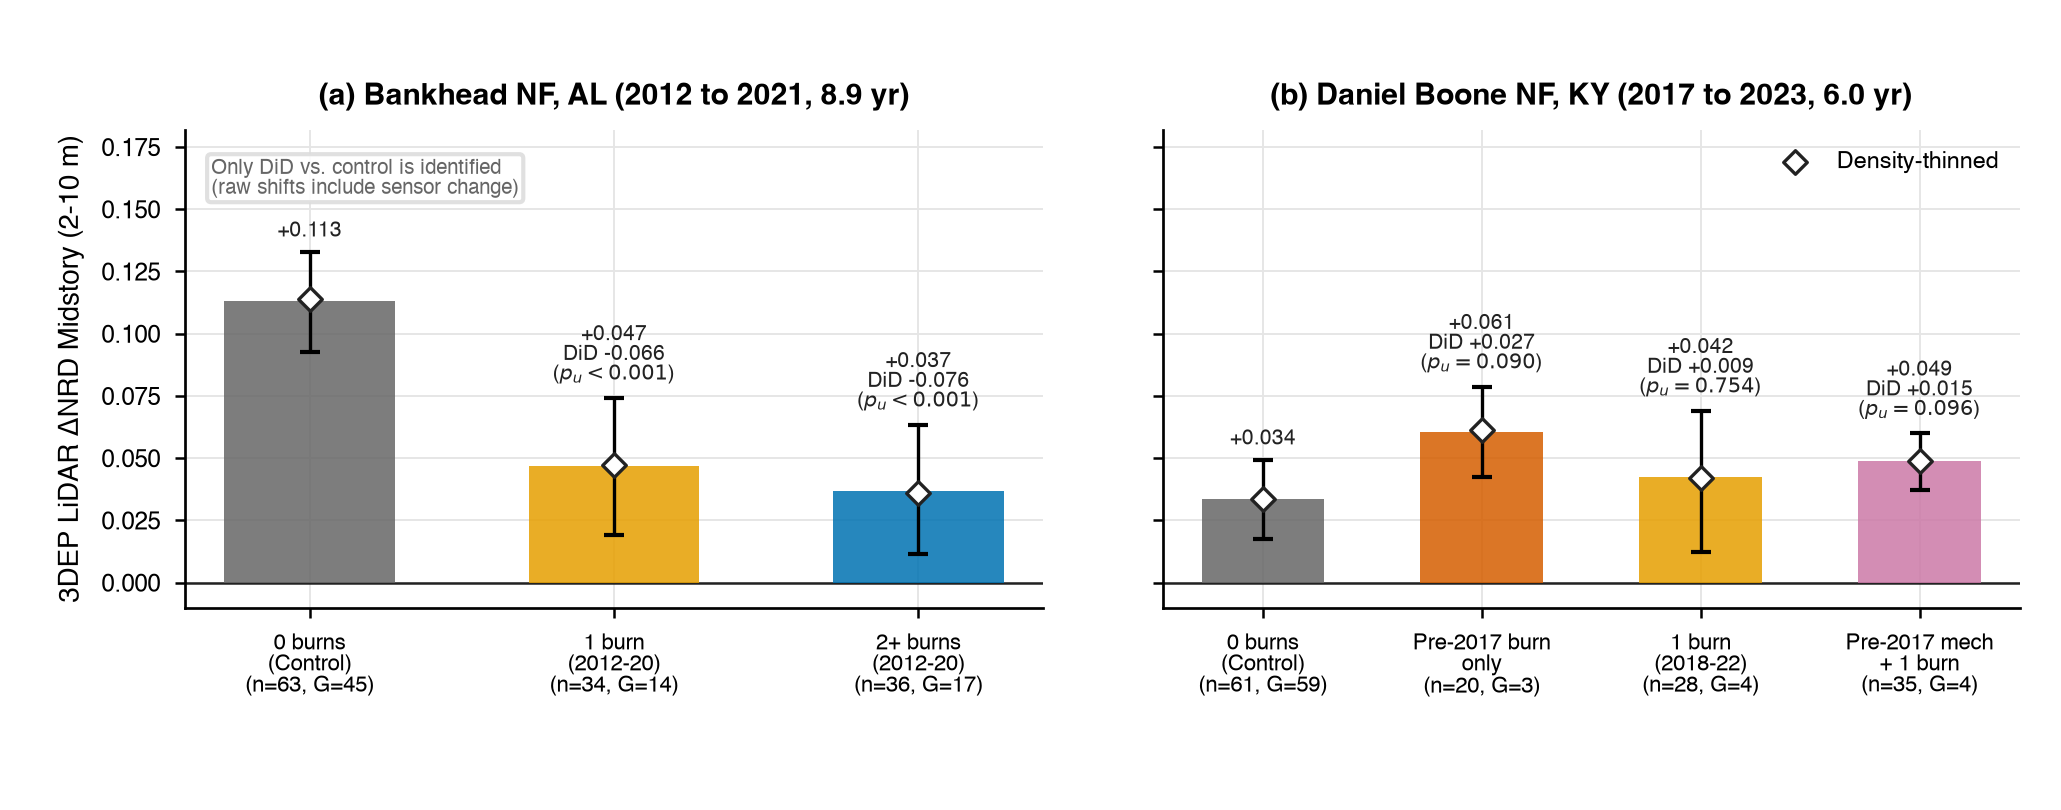

In [2]:
S = load("data/lidar/analysis_summary.json")
print("Total pure-deciduous plots:", S["n_total_plots"])
print("Plots by site:", S["plots_by_site"])
print("Plots by burn category:", S["plots_by_burn_cat"])

for site, bdata in S["baci"].items():
    fd = bdata.get("flight_diagnostics", {})
    print(f"\n=== BACI: {site} (n={bdata['n_total']}, excluded={bdata.get('n_excluded_off_epoch', 0)}, G_suid={bdata.get('n_clusters_suid')}, frac_first={fd.get('baseline_mean_frac_first_returns')}->{fd.get('primary_mean_frac_first_returns')}) ===")
    rows = []
    for st, d in bdata["strata"].items():
        dc = d.get("did_vs_control", {})
        rows.append({
            "stratum": st,
            "n": d["n"],
            "G_suid": d.get("n_clusters_suid"),
            "inter_mech": d.get("n_inter_mech_plots"),
            "base_mid": d["baseline_nrd_midstory"]["mean"],
            "end_mid": d["primary_nrd_midstory"]["mean"],
            "delta_mid": d["delta_nrd_midstory"]["mean"],
            "DiD_mid": dc.get("did_midstory"),
            "DiD_p_suid": dc.get("p_cluster_suid"),
            "DiD_p_wcb": dc.get("p_wcb_suid"),
            "DiD_thinned": dc.get("did_midstory_thinned"),
            "DiD_ancova": dc.get("did_midstory_ancova"),
            "p_ancova_suid": dc.get("p_ancova_suid"),
            "DiD_winNDVI": dc.get("did_opt_win_ndvi"),
            "DiD_sprNDVI": dc.get("did_opt_spr_ndvi"),
            "DiD_sprDB": dc.get("did_opt_spr_ndvi_db_epoch"),
        })
    display(pd.DataFrame(rows).set_index("stratum"))

show("paper/figures/fig2_baci_lidar_structural_change.png")

## 2. Continuous 1 m Vertical Profile, Unbiased First-Return Canopy & Direct Contrasts

,R2,1_burn,2_burns,3plus_burns,mech_plus_fire,mech_minus_3plus
target,,,,,,
p_nrd_understory,0.1874,-0.013 (p=0.002),-0.021 (p=0.000),-0.027 (p=0.000),-0.010 (p=0.069),+0.017 (p=0.002)
p_nrd_low_midstory,0.4101,-0.032 (p=0.000),-0.045 (p=0.000),-0.060 (p=0.000),-0.034 (p=0.000),+0.025 (p=0.014)
p_nrd_tall_midstory,0.2775,-0.023 (p=0.007),-0.014 (p=0.122),-0.017 (p=0.164),-0.042 (p=0.000),-0.024 (p=0.106)
p_nrd_midstory,0.3554,-0.046 (p=0.000),-0.050 (p=0.000),-0.064 (p=0.000),-0.067 (p=0.000),-0.003 (p=0.887)
p_first_return_canopy_10m,0.4131,-0.015 (p=0.362),+0.022 (p=0.193),+0.032 (p=0.117),-0.067 (p=0.001),-0.098 (p=0.000)
p_canopy_cover_10m,0.3943,+0.011 (p=0.316),+0.029 (p=0.002),+0.037 (p=0.002),-0.024 (p=0.056),-0.061 (p=0.000)
p_chm_p95,0.2541,+0.399 (p=0.384),+0.441 (p=0.256),-0.200 (p=0.721),+0.867 (p=0.233),+1.067 (p=0.227)
p_fhd,0.5444,-0.048 (p=0.167),-0.021 (p=0.436),-0.032 (p=0.299),-0.154 (p=0.000),-0.122 (p=0.006)
opt_win_ndvi,0.1919,-0.007 (p=0.283),-0.003 (p=0.632),+0.005 (p=0.352),-0.004 (p=0.564),-0.010 (p=0.204)



=== Continuous 1 m Vertical NRD Profile (0.5-10 m) ===


,3plus,p_3plus,mech,p_mech,mech_minus_3plus,p_contrast_suid
band_m,,,,,,
0.5_1,-0.00358,0.009063,-0.00144,0.425458,0.00214,0.264574
1_2,-0.02393,0.000000,-0.00860,0.053166,0.01534,0.000334
2_3,-0.02929,0.000000,-0.01327,0.000151,0.01602,0.000011
3_4,-0.02227,0.000000,-0.01268,0.000016,0.00959,0.010152
4_5,-0.01394,0.000434,-0.01119,0.000229,0.00275,0.581894
5_6,-0.00891,0.019840,-0.01073,0.000105,-0.00182,0.704059
6_7,-0.00608,0.075138,-0.01047,0.000006,-0.00439,0.283354
7_8,-0.00306,0.284972,-0.00932,0.000010,-0.00626,0.069495
8_9,-0.00175,0.488947,-0.00866,0.000013,-0.00690,0.023996


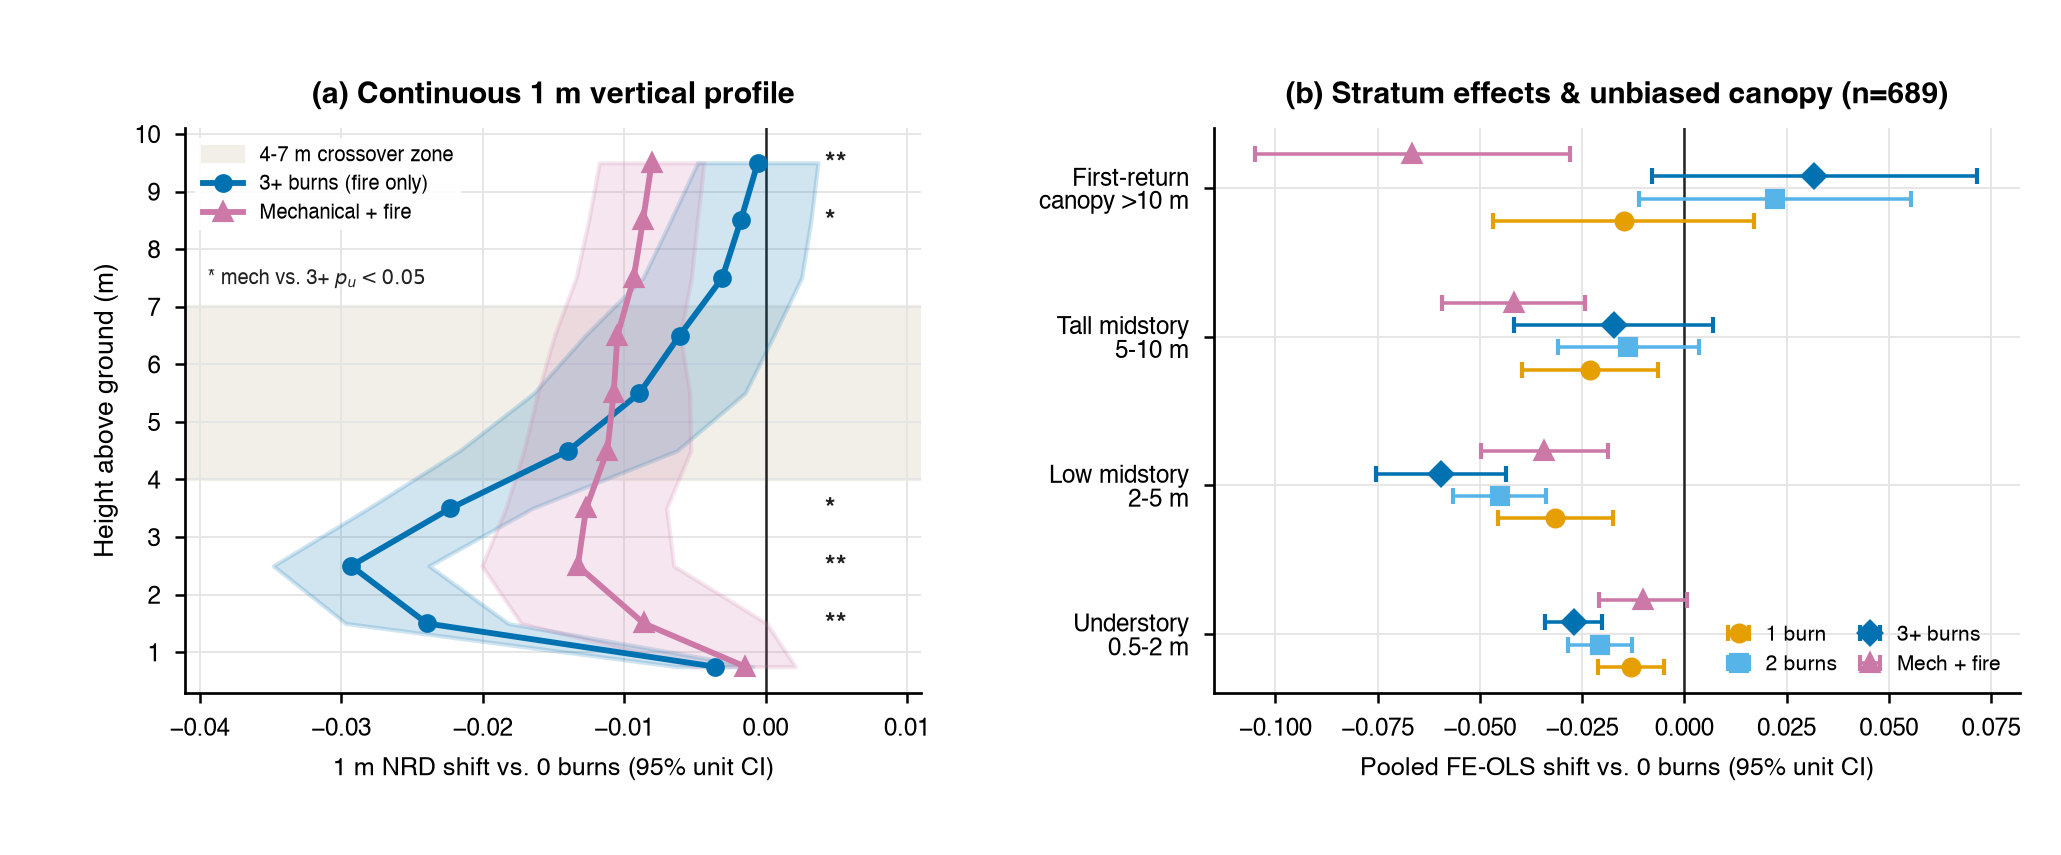

In [3]:
ols = S["pooled_fe_ols"]
rows = []
for target in ["p_nrd_understory", "p_nrd_low_midstory", "p_nrd_tall_midstory",
               "p_nrd_midstory", "p_first_return_canopy_10m", "p_canopy_cover_10m",
               "p_chm_p95", "p_fhd", "opt_win_ndvi", "opt_spr_ndvi"]:
    m = ols[target]
    cdict = m["coefs"]
    ct = m["contrasts"]["mech_minus_3plus"]
    rows.append({
        "target": target,
        "R2": m["r2"],
        "1_burn": f"{cdict['burn_1']['coef']:+.3f} (p={cdict['burn_1']['p_cluster_suid']:.3f})",
        "2_burns": f"{cdict['burn_2']['coef']:+.3f} (p={cdict['burn_2']['p_cluster_suid']:.3f})",
        "3plus_burns": f"{cdict['burn_3plus']['coef']:+.3f} (p={cdict['burn_3plus']['p_cluster_suid']:.3f})",
        "mech_plus_fire": f"{cdict['mech_plus_fire']['coef']:+.3f} (p={cdict['mech_plus_fire']['p_cluster_suid']:.3f})",
        "mech_minus_3plus": f"{ct['diff']:+.3f} (p={ct['p_cluster_suid']:.3f})",
    })
display(pd.DataFrame(rows).set_index("target"))

print("\n=== Continuous 1 m Vertical NRD Profile (0.5-10 m) ===")
p1m_rows = []
for lbl, m in S["pooled_fe_ols_1m_profile"].items():
    c = m["coefs"]
    ct = m["contrasts"]["mech_minus_3plus"]
    p1m_rows.append({
        "band_m": lbl,
        "3plus": c["burn_3plus"]["coef"],
        "p_3plus": c["burn_3plus"]["p_cluster_suid"],
        "mech": c["mech_plus_fire"]["coef"],
        "p_mech": c["mech_plus_fire"]["p_cluster_suid"],
        "mech_minus_3plus": ct["diff"],
        "p_contrast_suid": ct["p_cluster_suid"],
    })
display(pd.DataFrame(p1m_rows).set_index("band_m"))
show("paper/figures/fig3_vertical_stratum_decoupling.png")

## 3. Head-to-Head Sensor Validation (Pooled, Within-Site, and BACI Temporal Deltas)

In [4]:
sc = S["sensor_comparison"]
print("=== Cross-Sectional Pooled vs. Within-Site Correlations with 3DEP Midstory ===")
cs_df = pd.DataFrame({
    k: {
        "n": v["n"],
        "pooled_r": v["pearson_r_midstory"],
        "within_site_r": v["within_site_r_midstory"],
        "within_site_p": v["within_site_p_midstory"],
        "spearman_rho": v["spearman_rho_midstory"],
    }
    for k, v in sc["cross_sectional"].items()
}).T
display(cs_df)

print("\n=== Multi-Epoch BACI Temporal Delta Correlations (Winter & Spring Optical vs. 3DEP Midstory) ===")
bd_df = pd.DataFrame({
    k: {
        "n": v["n"],
        "pooled_r": v["pearson_r_d_midstory"],
        "pooled_p": v["p_d_midstory"],
        "within_site_r": v["within_site_r_d_midstory"],
        "within_site_p": v["within_site_p_d_midstory"],
    }
    for k, v in sc["baci_deltas"].items()
}).T
display(bd_df)

=== Cross-Sectional Pooled vs. Within-Site Correlations with 3DEP Midstory ===


,n,pooled_r,within_site_r,within_site_p,spearman_rho
opt_win_ndvi,678.0,0.3263,0.2769,0.000000,0.3598
opt_win_nbr,678.0,0.2364,0.1608,0.000026,0.3349
opt_win_ndmi,678.0,0.1783,0.1526,0.000066,0.3453
opt_spr_ndvi,689.0,0.4081,0.2961,0.000000,0.4130
opt_sum_ndvi,689.0,0.0059,0.0467,0.220678,-0.0026
opt_aut_ndvi,689.0,-0.1041,-0.0558,0.143189,-0.1411
gedi_pai_0_5m,359.0,0.1249,0.1949,0.000203,0.1308
gedi_pai_5_10m,359.0,0.1410,0.2926,0.000000,0.1774
gedi_pai_total,359.0,0.0152,0.1503,0.004314,0.0226
gedi_fhd,359.0,0.0024,0.0419,0.428821,-0.0756



=== Multi-Epoch BACI Temporal Delta Correlations (Winter & Spring Optical vs. 3DEP Midstory) ===


,n,pooled_r,pooled_p,within_site_r,within_site_p
d_opt_win_ndvi,272.0,-0.0013,0.983559,0.0087,0.886872
d_opt_win_nbr,272.0,-0.0707,0.244894,-0.0123,0.839495
d_opt_spr_ndvi,283.0,-0.0537,0.367735,0.0764,0.199838
d_opt_spr_ndvi_db_epoch,283.0,-0.0196,0.742642,-0.0687,0.249475
